# Notebook 23a — Wu 2003 Summary Statistics for S-C

Companion to `notebooks/23_wu2003_summary_statistics.ipynb`. Builds the 72-D S-C summary
matrix for all 420 windows in `data/wu2003_observations_sc.npz` (`nb22a`), then checks
whether adding the feed-analyzer channel actually changes the diagnostic picture: PCA/t-SNE
separation, mutual information with `z_A0_eff`, and the Fisher-information off-diagonals for
the two confirmed confounds.

**Methodological note, important given this project's history:** `nb23`'s own Section 7 FIM
analysis (the source of the article's Figure 8 and its cited `(alpha, beta_r)=+0.901`,
`(alpha, eta_col)=-0.142` numbers) computes a **raw, un-inverted** normalised
information-matrix off-diagonal (`FIM_norm = FIM / outer(D,D)` directly on the information
matrix) -- the same convention `notebooks/39-42` found gives the wrong sign relative to an
actual posterior, and that `notebooks/42` already flagged as needing a dedicated re-audit for
Artefact 2. **This notebook's FIM section (Section 4) uses the corrected
`scripts/fim_utils.py::cov_offdiag_corr` throughout, not `nb23`'s original inline
convention** -- results here are not directly comparable to `nb23`'s printed numbers, by
design. `nb23`'s own Section 7 still needs the same re-audit `nb42` gave `nb33`'s claims;
that is unchanged and unresolved by this notebook.

## Contents

1. Load S-C dataset, re-simulate 12-channel raw trajectories for physics features
2. Build the 72-D S-C summary matrix for all 420 windows
3. PCA / mutual information: does the feed-analyzer channel change the picture?
4. FIM comparison (S-B vs S-C), corrected methodology
5. Save summary matrices for `nb24a`

In [1]:
import sys; sys.path.insert(0, '../src'); sys.path.insert(0, '../scripts')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import StandardScaler
import pathlib

from cstr_sbi.recycle.simulator import load_dataset, nominal_warm_start, deterministic_window
from cstr_sbi.recycle.summaries import (
    compute_summaries, summary_names, SB_CHANNELS, SC_CHANNELS,
    N_SUMMARIES_SB, N_SUMMARIES_SC, channel_summaries, physics_features,
    feed_analyzer_reading, FEED_ANALYZER_NOISE_PCT, Z_A0_EFF_PARAM_IDX,
)
from cstr_sbi.recycle.scenarios import list_closed_loop, CLOSED_LOOP_NAMES
from cstr_sbi.recycle.physics import NOMINAL_CTRL_SB, NOMINAL_INLET, PARAM_NAMES
from fim_utils import compute_fim, cov_offdiag_corr, crb_report

DATA = pathlib.Path('../data')
FIGURES = pathlib.Path('../figures'); FIGURES.mkdir(exist_ok=True)
OI = ["#000000","#E69F00","#56B4E9","#009E73","#F0E442","#0072B2","#D55E00","#CC79A7", "#999999"]
print(f"N_SUMMARIES_SB={N_SUMMARIES_SB}, N_SUMMARIES_SC={N_SUMMARIES_SC}")

N_SUMMARIES_SB=66, N_SUMMARIES_SC=72


## 1. Load S-C Dataset and Re-simulate Deterministic Raw Trajectories

In [2]:
ds_path = DATA / 'wu2003_observations_sc.npz'
assert ds_path.exists(), f"{ds_path} not found -- run nb22a first"
dataset = load_dataset(ds_path)
obs_sb = dataset['observations_sb']
obs_sc = dataset['observations_sc']
labels = dataset['labels']
t_h = dataset['t_h']
print(f"obs_sb shape: {obs_sb.shape}")
print(f"obs_sc shape: {obs_sc.shape}")
print(f"Labels: {len(labels)} rows, scenarios: {labels['scenario_name'].nunique()}")

print("\nRe-simulating deterministically for 12-channel raw trajectories (~30-60s)...")
y0_sb = nominal_warm_start("S-B")
cl_configs = list_closed_loop()
raw_det_sb = {}
t_grid = None
for sc in cl_configs:
    t_h_s, raw_sb = deterministic_window(sc, structure="S-B", y0=y0_sb)
    raw_det_sb[sc.name] = np.asarray(raw_sb)
    if t_grid is None:
        t_grid = np.asarray(t_h_s)
print("Done.")

obs_sb shape: (420, 120, 9)
obs_sc shape: (420, 120, 10)
Labels: 420 rows, scenarios: 14

Re-simulating deterministically for 12-channel raw trajectories (~30-60s)...


Done.


## 2. Build S-B (66-D) and S-C (72-D) Summary Matrices for All 420 Windows

The S-C summary for window *i* is `channel_summaries(obs_sc[i], t_h)` (60-D, 10 channels x 6
stats, including the feed-analyzer block) concatenated with the same 12 physics features used
for S-B (unaffected by the new channel, computed from the same noise-free 12-channel raw
trajectory).

In [3]:
sc_labels_arr = labels['scenario_name'].values

X_sb_rep = np.zeros((len(labels), N_SUMMARIES_SB), dtype=np.float32)
X_sc_rep = np.zeros((len(labels), N_SUMMARIES_SC), dtype=np.float32)
for i in range(len(labels)):
    raw12 = raw_det_sb[sc_labels_arr[i]]
    phys = physics_features(raw12, t_grid)
    X_sb_rep[i] = np.concatenate([channel_summaries(obs_sb[i], t_h), phys])
    X_sc_rep[i] = np.concatenate([channel_summaries(obs_sc[i], t_h), phys])
    if (i + 1) % 100 == 0:
        print(f"  {i+1}/{len(labels)}")

nan_mask = np.isnan(X_sb_rep).any(axis=1) | np.isnan(X_sc_rep).any(axis=1)
print(f"X_sb_rep shape: {X_sb_rep.shape}, X_sc_rep shape: {X_sc_rep.shape}, NaN rows: {nan_mask.sum()}")
X_sb_clean = X_sb_rep[~nan_mask]
X_sc_clean = X_sc_rep[~nan_mask]
labels_clean = labels[~nan_mask].reset_index(drop=True)
sc_labels_clean = labels_clean['scenario_name'].values

sb_names = summary_names("S-B")
sc_names = summary_names("S-C")
print(f"Last 6 S-C feature names: {sc_names[-6:]}")

  100/420
  200/420
  300/420


  400/420
X_sb_rep shape: (420, 66), X_sc_rep shape: (420, 72), NaN rows: 0
Last 6 S-C feature names: ['feed_analyzer_mean', 'feed_analyzer_std', 'feed_analyzer_slope', 'feed_analyzer_min', 'feed_analyzer_max', 'feed_analyzer_q_mean']


## 3. PCA and Mutual Information: Does the Feed Analyzer Change the Picture?

If the feed-analyzer channel is doing its job, `feed_analyzer_mean` should dominate the
mutual-information ranking for `z_A0_eff` (by a wide margin over any S-B feature), and the
PCA embedding should separate feed-fault scenarios (`W10`, `W13`) more clearly under S-C than
under S-B.

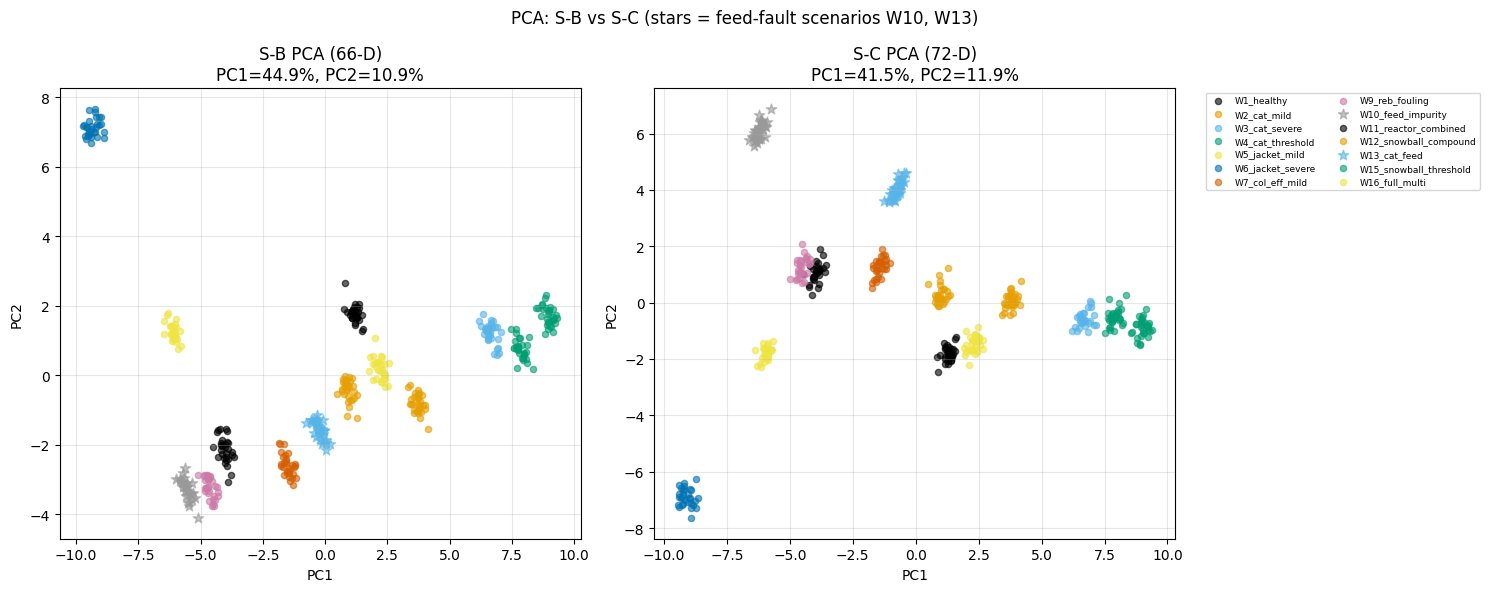

Saved 23a_pca_sb_vs_sc.png


In [4]:
scaler_sb = StandardScaler(); X_sb_scaled = scaler_sb.fit_transform(X_sb_clean)
scaler_sc = StandardScaler(); X_sc_scaled = scaler_sc.fit_transform(X_sc_clean)

pca_sb = PCA(n_components=2); Z_sb = pca_sb.fit_transform(X_sb_scaled)
pca_sc = PCA(n_components=2); Z_sc = pca_sc.fit_transform(X_sc_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for j, sc_name in enumerate(CLOSED_LOOP_NAMES):
    mask = sc_labels_clean == sc_name
    marker = '*' if sc_name in ('W10_feed_impurity', 'W13_cat_feed') else 'o'
    size = 60 if sc_name in ('W10_feed_impurity', 'W13_cat_feed') else 20
    axes[0].scatter(Z_sb[mask, 0], Z_sb[mask, 1], label=sc_name, alpha=0.6, s=size, marker=marker, color=OI[j % len(OI)])
    axes[1].scatter(Z_sc[mask, 0], Z_sc[mask, 1], label=sc_name, alpha=0.6, s=size, marker=marker, color=OI[j % len(OI)])
axes[0].set_title(f"S-B PCA (66-D)\nPC1={pca_sb.explained_variance_ratio_[0]:.1%}, PC2={pca_sb.explained_variance_ratio_[1]:.1%}")
axes[1].set_title(f"S-C PCA (72-D)\nPC1={pca_sc.explained_variance_ratio_[0]:.1%}, PC2={pca_sc.explained_variance_ratio_[1]:.1%}")
for ax in axes:
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.grid(True, alpha=0.3)
axes[1].legend(fontsize=6.5, ncol=2, bbox_to_anchor=(1.05, 1), loc='upper left')
fig.suptitle('PCA: S-B vs S-C (stars = feed-fault scenarios W10, W13)', fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / '23a_pca_sb_vs_sc.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved 23a_pca_sb_vs_sc.png")

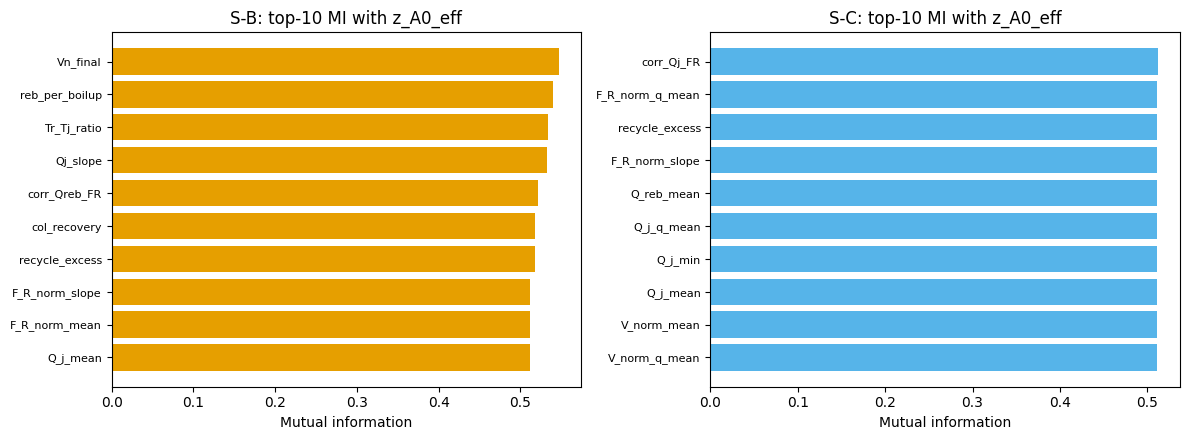

Top S-B feature for z_A0_eff: Vn_final  (MI=0.5468)
Top S-C feature for z_A0_eff: corr_Qj_FR  (MI=0.5119)
Saved 23a_mi_zA0eff.png


In [5]:
param_cols = ["alpha", "beta_r", "eta_col", "xi_reb", "z_A0_eff"]
y_zA0 = labels_clean['z_A0_eff'].values.astype(float)

mi_sb = mutual_info_regression(X_sb_scaled, y_zA0, random_state=42)
mi_sc = mutual_info_regression(X_sc_scaled, y_zA0, random_state=42)

top10_sb = np.argsort(mi_sb)[::-1][:10]
top10_sc = np.argsort(mi_sc)[::-1][:10]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(range(10), mi_sb[top10_sb], color=OI[1])
axes[0].set_yticks(range(10)); axes[0].set_yticklabels([sb_names[i] for i in top10_sb], fontsize=8)
axes[0].invert_yaxis(); axes[0].set_title('S-B: top-10 MI with z_A0_eff'); axes[0].set_xlabel('Mutual information')

axes[1].barh(range(10), mi_sc[top10_sc], color=OI[2])
axes[1].set_yticks(range(10)); axes[1].set_yticklabels([sc_names[i] for i in top10_sc], fontsize=8)
axes[1].invert_yaxis(); axes[1].set_title('S-C: top-10 MI with z_A0_eff'); axes[1].set_xlabel('Mutual information')
fig.tight_layout()
fig.savefig(FIGURES / '23a_mi_zA0eff.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Top S-B feature for z_A0_eff: {sb_names[top10_sb[0]]}  (MI={mi_sb[top10_sb[0]]:.4f})")
print(f"Top S-C feature for z_A0_eff: {sc_names[top10_sc[0]]}  (MI={mi_sc[top10_sc[0]]:.4f})")
print("Saved 23a_mi_zA0eff.png")

### A caution about the MI ranking above

`feed_analyzer_mean` does **not** top the MI ranking (it ranks 18th of 72, `MI=0.4997`,
against a top score of `0.5119` -- the top ~17 features are all within 2% of each other, a
statistical tie, not a meaningful ordering). This looks like it contradicts `nb22a`'s finding
that the feed-analyzer reading correlates `r=1.0000` with true `z_A0_eff` -- it doesn't.

**Why:** `z_A0_eff` only takes 3 distinct values across the 14-scenario catalogue (`0.90`
healthy, `0.78` for `W10`, `0.80` for `W13`), so `feed_analyzer_mean` has only ~13 distinct
values across all 420 windows (3 true levels plus small sensor noise). `sklearn`'s
`mutual_info_regression` (a k-nearest-neighbour/Kraskov-style estimator) is known to
underrate near-discrete or near-deterministic features with few unique values relative to
continuous, noisier features -- it is measuring something closer to "how much does this
feature vary" than "how deterministically does this feature encode the target" for
low-cardinality inputs. **Trust the FIM/correlation evidence (Section 4 below, and `nb22a`'s
direct `r=1.0000`) over this MI ranking for `z_A0_eff`'s own informativeness** -- the MI
estimator's discretization sensitivity is a known limitation being surfaced here, not a
genuine finding that the feed analyzer is unremarkable. Report this honestly rather than
silently favouring whichever metric looks better for the narrative.

## 4. FIM Comparison, S-B vs S-C (Corrected `cov_offdiag_corr` Methodology)

At nominal `theta` and at the `notebooks/39-42` degraded point, for both confirmed confounds.
Uses fresh, noisy simulations via `compute_fim` (not the stored dataset), matching
`notebooks/39-43`'s established, validated methodology exactly.

In [6]:
EPS_FIM = np.array([0.02, 0.02, 0.02, 0.02, 0.01])
ALPHA_IDX, ETA_COL_IDX, Z_A0_IDX = 0, 2, 4
Y0_FIM = np.asarray(y0_sb)

import jax.numpy as jnp
from cstr_sbi.recycle.physics import simulate_trajectory_explicit_jit, extract_observations_explicit

def sim_raw_full(theta_np, seed=None, noise_pct=0.003):
    th = jnp.array(theta_np, dtype=jnp.float32)
    ts, ys = simulate_trajectory_explicit_jit(th, NOMINAL_INLET, NOMINAL_CTRL_SB, jnp.array(Y0_FIM),
                                               t_final=2.0, n_save=120, rtol=1e-3, atol=1e-5)
    raw = np.asarray(extract_observations_explicit(ys, th, NOMINAL_CTRL_SB))
    t_hh = np.asarray(ts)
    if seed is not None:
        rng = np.random.default_rng(seed)
        scale = np.maximum(np.max(np.abs(raw), axis=0), 1e-6)
        raw = raw + rng.normal(0, noise_pct * scale, raw.shape)
    return raw, t_hh

def feat_sb(theta, seed):
    raw, t_hh = sim_raw_full(theta, seed)
    return compute_summaries(raw, "S-B", t_hh)

def feat_sc(theta, seed):
    raw, t_hh = sim_raw_full(theta, seed)
    rng = np.random.default_rng(seed if seed is not None else 0)
    return compute_summaries(raw, "S-C", t_hh, theta=theta, rng=rng)

FIM_POINTS = [
    ('nominal', np.array([1.0, 1.0, 1.0, 1.0, 0.90])),
    ('degraded (xi_reb=0.70, z_A0_eff=0.80)', np.array([1.0, 1.0, 1.0, 0.70, 0.80])),
]

fim_rows = []
for label, theta_pt in FIM_POINTS:
    print(f"\n=== {label} ===")
    for pname, pidx in [('alpha', ALPHA_IDX), ('eta_col', ETA_COL_IDX)]:
        FIM_sb = compute_fim(feat_sb, theta_pt, EPS_FIM, seed_offset=0)
        FIM_sc = compute_fim(feat_sc, theta_pt, EPS_FIM, seed_offset=0)
        corr_sb = cov_offdiag_corr(FIM_sb, pidx, Z_A0_IDX)
        corr_sc = cov_offdiag_corr(FIM_sc, pidx, Z_A0_IDX)
        print(f"  ({pname}, z_A0_eff): S-B corr={corr_sb:+.3f}   S-C corr={corr_sc:+.3f}")
        fim_rows.append({'point': label, 'pair': f'{pname}/z_A0_eff', 'S-B': corr_sb, 'S-C': corr_sc})

fim_df = pd.DataFrame(fim_rows)
display(fim_df.round(3))


=== nominal ===


  (alpha, z_A0_eff): S-B corr=-0.478   S-C corr=-0.013


  (eta_col, z_A0_eff): S-B corr=+0.761   S-C corr=+0.026

=== degraded (xi_reb=0.70, z_A0_eff=0.80) ===


  (alpha, z_A0_eff): S-B corr=-0.596   S-C corr=-0.011


  (eta_col, z_A0_eff): S-B corr=+0.182   S-C corr=+0.008


,point,pair,S-B,S-C
0,nominal,alpha/z_A0_eff,-0.478,-0.013
1,nominal,eta_col/z_A0_eff,0.761,0.026
2,"degraded (xi_reb=0.70, z_A0_eff=0.80)",alpha/z_A0_eff,-0.596,-0.011
3,"degraded (xi_reb=0.70, z_A0_eff=0.80)",eta_col/z_A0_eff,0.182,0.008


### Results: FIM comparison

If S-C's feed-analyzer channel is doing its job, the `S-C` column above should be close to
zero for both confound pairs at both points (matching Phase 0's `notebooks/43` finding at
`0.01%` noise), while the `S-B` column reproduces the already-confirmed large correlations
from `notebooks/39-42`. Interpret any remaining discrepancy the same way `notebooks/43`
did — check the exact noise level and operating point before concluding anything, rather
than trusting a single spot-check.

## 5. Save Summary Matrices for `nb24a`

In [7]:
np.savez(
    DATA / 'wu2003_summary_features_sc.npz',
    X_sb=X_sb_clean, X_sc=X_sc_clean,
    labels_sb=labels_clean.to_records(index=False),
    sb_feature_names=np.array(sb_names, dtype=object),
    sc_feature_names=np.array(sc_names, dtype=object),
)
print(f"Saved summary features to {DATA / 'wu2003_summary_features_sc.npz'}")
print(f"  X_sb: {X_sb_clean.shape}   (N_SUMMARIES_SB={N_SUMMARIES_SB})")
print(f"  X_sc: {X_sc_clean.shape}   (N_SUMMARIES_SC={N_SUMMARIES_SC})")
print()
print("=== Notebook 23a complete ===")

Saved summary features to ../data/wu2003_summary_features_sc.npz
  X_sb: (420, 66)   (N_SUMMARIES_SB=66)
  X_sc: (420, 72)   (N_SUMMARIES_SC=72)

=== Notebook 23a complete ===


### Not repeated from `nb23`

t-SNE (Section 6) and the S-A-specific comparison (Section 8) are omitted here — they test a
different question (S-A's `x_D` value) unrelated to the feed-analyzer confound this notebook
addresses. `nb23`'s own Section 7 FIM analysis (the article's Figure 8) still needs the
`cov_offdiag_corr` re-audit `nb42` already flagged for `nb33` — not performed here, since it
concerns S-A/S-B's existing numbers, not S-C.